# Fashion-MNIST Classification Using a Fully Connected Neural Network


## 1. Fashion-MNIST Dataset


### Loading the Fashion-MNIST Dataset


In [ ]:
import torch
from torch.utils.data import Dataset
from torchvision import datasets
from torchvision.transforms import ToTensor
from matplotlib import pyplot as plt
from torch import nn

dataset_train = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor()
)
dataset_val = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor()
)

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 204kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.79MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 26.2MB/s]


### Inspecting the Dataset Structure


In [ ]:
print(type(dataset_train[0]))
print(len(dataset_train[0]))

<class 'tuple'>
2


### Visualizing the First Sample


<class 'torch.Tensor'> <class 'int'>
torch.Size([1, 28, 28])
torch.float32
tensor(1.) tensor(0.)
9
torch.Size([28, 28])


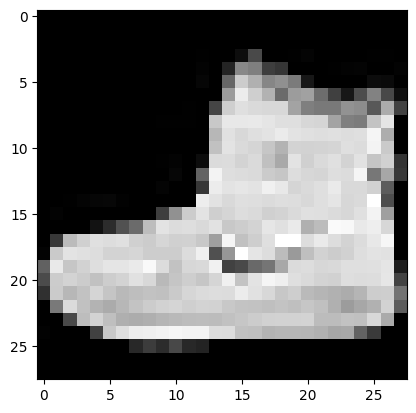

In [ ]:
img, label = dataset_train[0]
print(type(img), type(label))
print(img.shape)
print(img.dtype)
print(img.max(), img.min())
print(label)
print(img.squeeze().shape)
plt.imshow(img.squeeze(), cmap='gray')
plt.show()

### Visualizing the Second Sample


<class 'torch.Tensor'> <class 'int'>
torch.Size([1, 28, 28])
torch.float32
tensor(1.) tensor(0.)
0
torch.Size([28, 28])


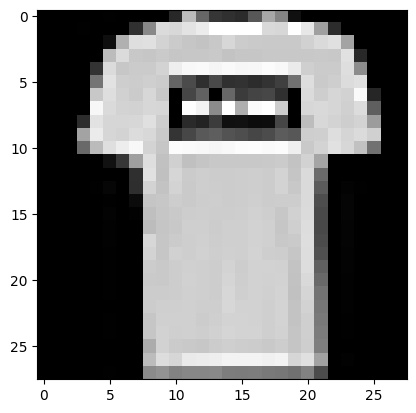

In [ ]:
img, label = dataset_train[1]
print(type(img), type(label))
print(img.shape)
print(img.dtype)
print(img.max(), img.min())
print(label)
print(img.squeeze().shape)
plt.imshow(img.squeeze(), cmap='gray')
plt.show()

## 2. Synthetic Data for Batch Practice


### Generating Sample Temperature Data


In [ ]:
import torch

base = 20
heatup_per_sec = 0.25

seconds_start = 60
seconds_ends = 300
num_samples = 100
error_scale = 5

seconds = torch.randint(seconds_start, seconds_ends,
                        [num_samples, 1]).float()
random_error = torch.randn([num_samples, 1]) * error_scale
temps = base + heatup_per_sec * seconds + random_error

### Inspecting Generated Data


In [ ]:
print(seconds)
print(temps)

tensor([[ 97.],
        [292.],
        [269.],
        [ 61.],
        [221.],
        [207.],
        [129.],
        [283.],
        [149.],
        [270.],
        [252.],
        [261.],
        [264.],
        [ 84.],
        [136.],
        [259.],
        [288.],
        [ 85.],
        [259.],
        [ 97.],
        [238.],
        [279.],
        [192.],
        [ 98.],
        [233.],
        [ 84.],
        [194.],
        [137.],
        [285.],
        [261.],
        [142.],
        [ 82.],
        [166.],
        [220.],
        [221.],
        [192.],
        [ 80.],
        [276.],
        [157.],
        [293.],
        [224.],
        [ 85.],
        [154.],
        [230.],
        [261.],
        [121.],
        [ 97.],
        [287.],
        [193.],
        [261.],
        [169.],
        [264.],
        [287.],
        [ 70.],
        [ 75.],
        [ 82.],
        [111.],
        [238.],
        [286.],
        [ 75.],
        [298.],
        [107.],
        

## 3. Loading Data in Mini-Batches


### Creating Training and Validation DataLoaders


In [ ]:
from torch.utils.data import DataLoader

dataloader_train = DataLoader(dataset_train, batch_size=64, shuffle=True)
for img, label in dataloader_train:
    print(img.shape)
    print(label.shape)
    print(label)
    break

dataloader_val = DataLoader(dataset_val, batch_size=64, shuffle=False)

torch.Size([64, 1, 28, 28])
torch.Size([64])
tensor([5, 9, 9, 5, 0, 2, 1, 6, 8, 0, 0, 1, 0, 0, 3, 0, 7, 0, 8, 4, 4, 0, 9, 9,
        3, 4, 5, 4, 3, 0, 7, 7, 2, 4, 3, 3, 7, 7, 4, 2, 7, 3, 4, 8, 1, 3, 5, 6,
        3, 0, 1, 3, 6, 2, 6, 8, 2, 5, 4, 4, 4, 5, 0, 0])


## 4. Fully Connected Neural Network


### Defining the Neural Network Model


In [ ]:
f = nn.Sequential(nn.Flatten(),
                  nn.Linear(28*28, 512),
                  nn.ReLU(),
                  nn.Linear(512, 256),
                  nn.ReLU(),
                  nn.Linear(256, 10)).cuda()

### Testing Model Predictions


In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
X = torch.rand(4, 1, 28, 28, device=device)
logits = f(X)
print(logits)
pred_prob = nn.Softmax(dim=1)(logits)
print(pred_prob)
y_pred = pred_prob.argmax(1)
print(f"Predicted class: {y_pred}")

tensor([[-0.0448,  0.0445,  0.1723, -0.0578,  0.0517, -0.1201,  0.0511, -0.0556,
         -0.0348, -0.0195],
        [-0.0183,  0.0298,  0.1412, -0.0158,  0.0245, -0.1048,  0.0238, -0.0703,
         -0.0216, -0.0212],
        [-0.0186,  0.0728,  0.1234, -0.0365,  0.0804, -0.1031,  0.0398, -0.0447,
         -0.0485, -0.0602],
        [-0.0528, -0.0071,  0.1957, -0.0197,  0.0449, -0.1421,  0.0112, -0.0368,
         -0.0389, -0.0468]], device='cuda:0', grad_fn=<AddmmBackward0>)
tensor([[0.0954, 0.1044, 0.1186, 0.0942, 0.1051, 0.0885, 0.1051, 0.0944, 0.0964,
         0.0979],
        [0.0983, 0.1032, 0.1153, 0.0986, 0.1026, 0.0902, 0.1025, 0.0933, 0.0980,
         0.0980],
        [0.0979, 0.1072, 0.1128, 0.0961, 0.1081, 0.0899, 0.1038, 0.0954, 0.0950,
         0.0939],
        [0.0954, 0.0999, 0.1223, 0.0986, 0.1052, 0.0873, 0.1017, 0.0969, 0.0967,
         0.0960]], device='cuda:0', grad_fn=<SoftmaxBackward0>)
Predicted class: tensor([2, 2, 2, 2], device='cuda:0')


### Defining the Validation Function


In [ ]:
@torch.no_grad()
def validate(f, dataloader):
    num_correct = 0
    num_total = 0
    for images, labels in tqdm(dataloader, total=len(dataloader)):
        images = images.to(device)
        labels = labels.to(device)
        logits = f(images)
        prediction = logits.argmax(dim=1)
        num_correct += (prediction == labels).type(torch.float).sum().item()
        num_total += len(labels)
    return num_correct / num_total

### Model Training — First Pass


  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

...

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

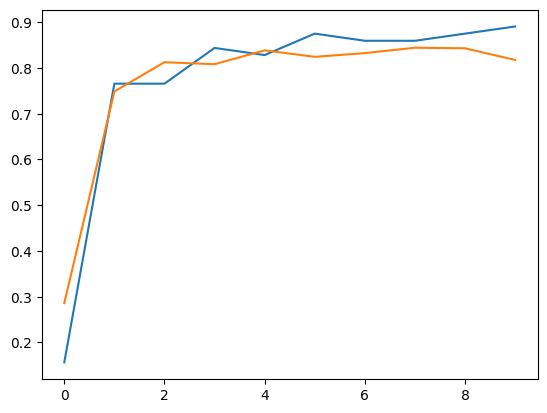

In [ ]:
from tqdm.notebook import tqdm
ce = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(f.parameters(), lr=1e-3)
accuracies_train = []
accuracies_val = []
for i, (images, labels) in tqdm(enumerate(dataloader_train),
                                total=len(dataloader_train)):

    images = images.to(device)
    labels = labels.to(device)
    logits = f(images)
    loss = ce(logits, labels)
    # print(loss)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    # break;
    if i % 100 == 0:
        prediction = logits.argmax(dim=1)
        num_correct = (prediction == labels).type(torch.float).sum().item()
        accuracy_train = num_correct / len(labels)
        accuracies_train.append(accuracy_train)
        accuracy_val = validate(f, dataloader_val)
        accuracies_val.append(accuracy_val)

plt.plot(accuracies_train)
plt.plot(accuracies_val)
plt.show()

### Model Training — Second Pass


  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

...

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

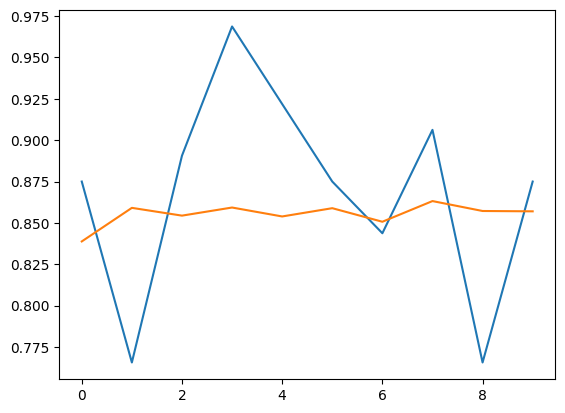

In [ ]:
from tqdm.notebook import tqdm
ce = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(f.parameters(), lr=1e-3)
accuracies_train = []
accuracies_val = []
for i, (images, labels) in tqdm(enumerate(dataloader_train),
                                total=len(dataloader_train)):

    images = images.to(device)
    labels = labels.to(device)
    logits = f(images)
    loss = ce(logits, labels)
    # print(loss)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    # break;
    if i % 100 == 0:
        prediction = logits.argmax(dim=1)
        num_correct = (prediction == labels).type(torch.float).sum().item()
        accuracy_train = num_correct / len(labels)
        accuracies_train.append(accuracy_train)
        accuracy_val = validate(f, dataloader_val)
        accuracies_val.append(accuracy_val)

plt.plot(accuracies_train)
plt.plot(accuracies_val)
plt.show()